Alessia Stefanelli - 615430

# Data Understanding - Dati Tabulari - `wellness.csv`

Esplorazione di ciascun dataset, inizialmente, separatamente

### **Informazioni Generali**


In [1]:
# Caricamento librerie necessarie all'analisi dei dataset nei file CSV
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict

import seaborn as sns

from scipy.stats import pearsonr


In [2]:
wellness_df = pd.read_csv('../datasets/patients_wellness.csv', low_memory=False)
patients_df = pd.read_csv('../datasets/patients.csv')

In [3]:
wellness_df

,Unnamed: 0,subject_id,BloodPressure,Weight,BMI,Height,BloodPressureStanding1,BloodPressureLying,BloodPressureSitting,BloodPressureStanding3,BloodPressureStanding,Weight2,eGFR
0,0,10000032,110/65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,10000084,NaN,94.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,10000117,NaN,NaN,18.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,10000248,NaN,NaN,NaN,60.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,10000280,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
158311,158311,19999636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
158312,158312,19999733,120/74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
158313,158313,19999750,NaN,NaN,28.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
158314,158314,19999784,NaN,NaN,NaN,61.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### **Osservazione**:  
**Temporary Cleaning** :`Unnamed: 0` dovranno essere rimosse durante la Data Preparation, poiche non hanno un significato apparente

In [4]:
# temp cleaning
wellness_df  = wellness_df.drop(columns=["Unnamed: 0"])

In [5]:
# num of record and attribute
print("Dim del dataset:", wellness_df.shape)

Dim del dataset: (158316, 12)


In [6]:
wellness_df.columns

Index(['subject_id', 'BloodPressure', 'Weight', 'BMI', 'Height',
       'BloodPressureStanding1', 'BloodPressureLying', 'BloodPressureSitting',
       'BloodPressureStanding3', 'BloodPressureStanding', 'Weight2', 'eGFR'],
      dtype='object')

In [7]:
# Informazioni sul dataset
wellness_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158316 entries, 0 to 158315
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   subject_id              158316 non-null  int64  
 1   BloodPressure           3360 non-null    object 
 2   Weight                  3664 non-null    float64
 3   BMI                     3337 non-null    float64
 4   Height                  3222 non-null    float64
 5   BloodPressureStanding1  36 non-null      object 
 6   BloodPressureLying      37 non-null      object 
 7   BloodPressureSitting    48 non-null      object 
 8   BloodPressureStanding3  0 non-null       float64
 9   BloodPressureStanding   8 non-null       object 
 10  Weight2                 7 non-null       float64
 11  eGFR                    6 non-null       object 
dtypes: float64(5), int64(1), object(6)
memory usage: 14.5+ MB


---
### **Dupplicati**

In [8]:
num_duplicates = wellness_df.duplicated().sum()
print("Numero di righe duplicate:", num_duplicates)

Numero di righe duplicate: 0


In [9]:
# Trova duplicati basati su una colonna specifica come 'subject_id'
duplicates_subject = wellness_df[wellness_df.duplicated(subset=['subject_id'])]
print("Numero di duplicati basati su 'subject_id':", len(duplicates_subject))


Numero di duplicati basati su 'subject_id': 0


---
### **Valori Mancanti**

In [10]:
# Controlla che ci siano tutti i subjecy_id anche nel dataset principale (patients_df)
wellness_subject_ids = set(wellness_df['subject_id'].unique())
patients_subject_ids = set(patients_df['subject_id'].unique())

missing_subject_ids = wellness_subject_ids - patients_subject_ids
num_missing_subject_ids = len(missing_subject_ids)
total_subject_ids = len(wellness_subject_ids)
percentage_missing = (num_missing_subject_ids / total_subject_ids) * 100

print(f"Numero di subject_id in wellness_df ma non in patients_df: {num_missing_subject_ids}")
print(f"Percentuale di subject_id in wellness_df ma non in patients_df : {percentage_missing:.2f}%")


Numero di subject_id in wellness_df ma non in patients_df: 127133
Percentuale di subject_id in wellness_df ma non in patients_df : 80.30%


In [11]:
# Conta valori NaN in ogni colonna
print(wellness_df.isnull().sum())

subject_id                     0
BloodPressure             154956
Weight                    154652
BMI                       154979
Height                    155094
BloodPressureStanding1    158280
BloodPressureLying        158279
BloodPressureSitting      158268
BloodPressureStanding3    158316
BloodPressureStanding     158308
Weight2                   158309
eGFR                      158310
dtype: int64


In [12]:
subset_column = ['BloodPressure', 'Weight', 'BMI', 'Height',
                 'BloodPressureStanding1', 'BloodPressureLying', 'BloodPressureSitting',
                 'BloodPressureStanding3', 'BloodPressureStanding', 'Weight2', 'eGFR']

In [13]:
# Calcola la percentuale di valori mancanti
missing_percentage = (wellness_df[subset_column].isnull().sum() / len(wellness_df)) * 100
print("Percentuale di valori mancanti:")
print(missing_percentage)

Percentuale di valori mancanti:
BloodPressure              97.877662
Weight                     97.685641
BMI                        97.892190
Height                     97.964830
BloodPressureStanding1     99.977261
BloodPressureLying         99.976629
BloodPressureSitting       99.969681
BloodPressureStanding3    100.000000
BloodPressureStanding      99.994947
Weight2                    99.995578
eGFR                       99.996210
dtype: float64


In [14]:
# Conta le righe con almeno un valore mancante
rows_any_nan = wellness_df[wellness_df.isnull().any(axis=1)]
print("Totale righe nel dataset: ", len(wellness_df))
print("Totale righe con almeno un NaN: ",  len(rows_any_nan))
print("Numero di righe senza nemmeno un NaN:", len(wellness_df) - len(rows_any_nan))


Totale righe nel dataset:  158316
Totale righe con almeno un NaN:  158316
Numero di righe senza nemmeno un NaN: 0


In [15]:
# Conta le righe interamente vuote
rows_all_nan = wellness_df.dropna(how='all', subset=subset_column)
print(subset_column)
print("Numero di righe con tutti NaN per tutte le colonne selezionate:", len(wellness_df) - len(rows_all_nan))

['BloodPressure', 'Weight', 'BMI', 'Height', 'BloodPressureStanding1', 'BloodPressureLying', 'BloodPressureSitting', 'BloodPressureStanding3', 'BloodPressureStanding', 'Weight2', 'eGFR']
Numero di righe con tutti NaN per tutte le colonne selezionate: 144591


In [16]:
# Verifica i valori mancanti per le colonne essenziali, prima e dopo la rimozione dei 144591
tmp_df = wellness_df.dropna(how='all', subset=subset_column)

tmp_df[subset_column].isnull().sum()
print("Valori mancanti per le colonne essenziali PRIMA della rimozione:")
print(wellness_df[subset_column].isnull().sum())
print("-"*50, "\n")
print("Valori mancanti per le colonne essenziali DOPO la rimozione:")
print(tmp_df[subset_column].isnull().sum())
print(len(tmp_df))
print("Percentuale restanti: ", len(tmp_df)/len(wellness_df)*100)


Valori mancanti per le colonne essenziali PRIMA della rimozione:
BloodPressure             154956
Weight                    154652
BMI                       154979
Height                    155094
BloodPressureStanding1    158280
BloodPressureLying        158279
BloodPressureSitting      158268
BloodPressureStanding3    158316
BloodPressureStanding     158308
Weight2                   158309
eGFR                      158310
dtype: int64
-------------------------------------------------- 

Valori mancanti per le colonne essenziali DOPO la rimozione:
BloodPressure             10365
Weight                    10061
BMI                       10388
Height                    10503
BloodPressureStanding1    13689
BloodPressureLying        13688
BloodPressureSitting      13677
BloodPressureStanding3    13725
BloodPressureStanding     13717
Weight2                   13718
eGFR                      13719
dtype: int64
13725
Percentuale restanti:  8.669370120518456


**Osservazione:** Per i restanti usare media, mediana o altri valori specifici appropriati. Oppure direttamente cancellarli

In [17]:
# Togliere riga appena c'e' almeno un NaN in una colonna
tmp_df_all_na = wellness_df.dropna()
print(len(tmp_df_all_na))
print("Percentuale restanti: ", len(tmp_df_all_na)/len(wellness_df)*100)

0
Percentuale restanti:  0.0


**Osservazione**: O cancellare il dataset o aggiungere i valori mancanti con un valore appropriato

---
### **Statistiche Descrittive + Distribuzione + Analisi outlier**

In [18]:
print(wellness_df.dtypes)

subject_id                  int64
BloodPressure              object
Weight                    float64
BMI                       float64
Height                    float64
BloodPressureStanding1     object
BloodPressureLying         object
BloodPressureSitting       object
BloodPressureStanding3    float64
BloodPressureStanding      object
Weight2                   float64
eGFR                       object
dtype: object


In [19]:
obj_column = ['BloodPressure', 'BloodPressureStanding1', 'BloodPressureLying', 'BloodPressureSitting','BloodPressureStanding', 'eGFR']
for column in obj_column:
    print(f"\nValori unici per [{column}]\n")
    print(wellness_df[column].unique())
    print("-"*50, "\n")


Valori unici per [BloodPressure]

['110/65' nan '124/66' ... '122/46' '102/62' '128/83']
-------------------------------------------------- 


Valori unici per [BloodPressureStanding1]

[nan '120/70' '144/87' '110/60' '106/46' '116/110' '130/92' '160/104'
 '117/69' '118/64' '95/60' '94/60' '192/67' '140/102' '110/65' '122/80'
 '85/59' '112/60' '126/72' '101/65' '108/60' '150/90' '58/0' '115/57'
 '92/64' '104/55' '118/80' '100/70' '90/60' '109/80' '114/51' '110/68'
 '118/74' '98/68' '120/85']
-------------------------------------------------- 


Valori unici per [BloodPressureLying]

[nan '145/87' '114/60' '109/47' '130/80' '122/73' '188/118' '136/91'
 '174/94' '111/67' '98/61' '124/70' '120/60' '144/90' '85/40' '97/65'
 '145/55' '108/76' '140/101' '112/70' '103/76' '112/60' '118/72' '127/76'
 '114/62' '150/102' '114/58' '166/83' '109/69' '149/76' '108/72' '112/76'
 '119/58' '105/65' '120/50' '112/78' '140/60']
-------------------------------------------------- 


Valori unici per [Blo

**Osservazione**: In verita gli attributi `object` sono tutti stringhe di frazioni.\
 Apparte in `eGFR` dove c'e' `>60`

In [20]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
subset_column_num = ['Weight', 'BMI', 'Height', 'Weight2']
print(wellness_df[subset_column_num].describe())

            Weight          BMI       Height     Weight2
count  3664.000000  3337.000000  3222.000000    7.000000
mean    176.772451    31.322056    65.852028  161.285714
std      56.481010   110.848306     4.746027   28.235405
min       1.000000     0.200000     1.000000  130.000000
25%     141.995000    23.700000    63.000000  139.000000
50%     170.000000    27.400000    66.000000  164.000000
75%     202.000000    32.000000    69.000000  173.500000
max    1741.900000  4649.400000   108.000000  210.000000


In [21]:
# Calcola il range delle colonne numeriche
print("Range per ciascuna variabile numerica :")
for column in subset_column_num:
    print(f"- {column}: MIN: [", wellness_df[column].min(),"]       MAX: [",  wellness_df[column].max(), ']')


Range per ciascuna variabile numerica :
- Weight: MIN: [ 1.0 ]       MAX: [ 1741.9 ]
- BMI: MIN: [ 0.2 ]       MAX: [ 4649.4 ]
- Height: MIN: [ 1.0 ]       MAX: [ 108.0 ]
- Weight2: MIN: [ 130.0 ]       MAX: [ 210.0 ]


Per ogni attributo numerico, è stato definito un range di valori accettabili, considerando che i pazienti sono adulti:
- `Weight` (https://www.msdmanuals.com/it/professionale/multimedia/table/indice-di-massa-corporea): 
    $\text{Se } X \notin [30, 300] \Rightarrow X \text{ è un outlier}$
    - malnutrizione severa: 30 kg
    - obesità estrema: 300 kg
- `BMI` (https://en.wikipedia.org/wiki/Body_mass_index):  
    $\text{Se } X \notin [12, 60] \Rightarrow X \text{ è un outlier}$
    - grave malnutrizione : inferiore a 12 kg/m²
    - gravi rischi per la salute: superiore a 60 kg/m² 
- `Height`:
     $\text{Se } X \notin [23.6, 98.4] \Rightarrow X \text{ è un outlier}$
     - nanismo severo: valori inferiore a 23,6 pollici (60 cm)
     - gigantismo estremo: superiore a 98.4 pollici (250 cm)
Li dove non e' stato trovato un valore estremo e' stato messo un estremo che, se esiste, solo pochissimi hanno quelle condizioni.

In [22]:
acceptable = wellness_df[(wellness_df['Weight'] >= 30) & (wellness_df['Weight'] <= 300)]
df_non_null = wellness_df[wellness_df['Weight'].notna()]
print("Numero di righe con Weight accettale (30-300 kg):", len(acceptable))
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con Weight accettale (30-300 kg): 3602
Num outlier : 62


In [23]:
acceptable = wellness_df[(wellness_df['Weight2'] >= 30) & (wellness_df['Weight2'] <= 300)]
df_non_null = wellness_df[wellness_df['Weight2'].notna()]
print("Numero di righe con Weight2 accettale (30-300 kg):", len(acceptable))
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con Weight2 accettale (30-300 kg): 7
Num outlier : 0


In [24]:
acceptable = wellness_df[(wellness_df['BMI'] >= 12) & (wellness_df['BMI'] <= 60)]
print("Numero di righe con BMI accettale (12-60 bpm):", len(acceptable))
df_non_null = wellness_df[wellness_df['BMI'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con BMI accettale (12-60 bpm): 3319
Num outlier : 18


In [25]:
acceptable = wellness_df[(wellness_df['Height'] >= 23.6) & (wellness_df['Height'] <= 98.4)]
print("Numero di righe con Height accettabile (23,6-98.4 atti):", len(acceptable))
df_non_null = wellness_df[wellness_df['Height'].notna()]
print("Num outlier :", len(df_non_null) - len(acceptable))

Numero di righe con Height accettabile (23,6-98.4 atti): 3216
Num outlier : 6


In [32]:
# Weight - BMI - Height - Weight2
outlier = [(tmp_df_all_na['Weight'] < 8) & (tmp_df_all_na['Weight'] > 40) & (tmp_df_all_na['BMI'] < 82) & (tmp_df_all_na['BMI'] > 105.8) & (tmp_df_all_na['Height'] < 40) & (tmp_df_all_na['Height'] > 220) & (tmp_df_all_na['Weight2'] < 80) & (tmp_df_all_na['Weight2'] > 100)]

print("Numero di righe non accettabili :", len(outlier))
print("Dataset totale di triage privo di NaN", len(tmp_df_all_na))
print("Percentuale restanti sul dataset triage.csv privo di NaN: ", (len(tmp_df_all_na) - len(outlier))/len(wellness_df)*100)
# outlier


Numero di righe non accettabili : 1
Dataset totale di triage privo di NaN 0
Percentuale restanti sul dataset triage.csv privo di NaN:  -0.0006316480962126381


---
### **5. Valori Unici e Distribuzione Categoriale**

In [28]:
# Visualizza i tipi di dati per identificare le colonne categoriali
print("Tipi di dati nel dataset:")
print(wellness_df.dtypes)
print(wellness_df.columns)

Tipi di dati nel dataset:
subject_id                  int64
BloodPressure              object
Weight                    float64
BMI                       float64
Height                    float64
BloodPressureStanding1     object
BloodPressureLying         object
BloodPressureSitting       object
BloodPressureStanding3    float64
BloodPressureStanding      object
Weight2                   float64
eGFR                       object
dtype: object
Index(['subject_id', 'BloodPressure', 'Weight', 'BMI', 'Height',
       'BloodPressureStanding1', 'BloodPressureLying', 'BloodPressureSitting',
       'BloodPressureStanding3', 'BloodPressureStanding', 'Weight2', 'eGFR'],
      dtype='object')


In [29]:
# Unique value comprehension
for column in wellness_df.columns:
    print(f"\t\t======= UNIQUE VALUE in [{column}] =======\n")
    print(wellness_df[column].unique())
    print("\n\t\t=== Frequency of unique value ===\n")
    print(wellness_df[column].value_counts())
    print("-" * 60, "\n")


		======= UNIQUE VALUE in [subject_id] =======

[10000032 10000084 10000117 ... 19999750 19999784 19999828]

		=== Frequency of unique value ===

subject_id
10000032    1
16683512    1
16683134    1
16683197    1
16683251    1
           ..
13350569    1
13350579    1
13350607    1
13350693    1
19999828    1
Name: count, Length: 158316, dtype: int64
------------------------------------------------------------ 

		======= UNIQUE VALUE in [BloodPressure] =======

['110/65' nan '124/66' ... '122/46' '102/62' '128/83']

		=== Frequency of unique value ===

BloodPressure
110/70     61
120/80     57
120/70     55
130/80     54
100/60     31
           ..
151/108     1
136/56      1
120/67      1
142/85      1
128/83      1
Name: count, Length: 1466, dtype: int64
------------------------------------------------------------ 

		======= UNIQUE VALUE in [Weight] =======

[   nan  94.   170.   ... 137.8  149.1  116.62]

		=== Frequency of unique value ===

Weight
150.00    55
200.00    52
140.00

---
### **6. Correlazione matrice**


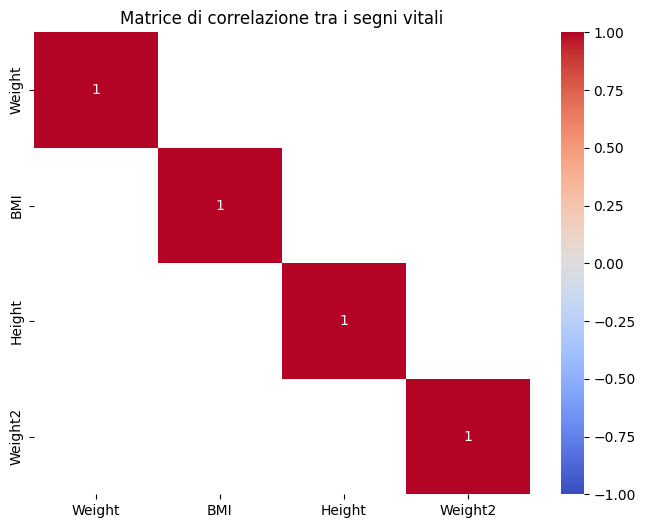

In [30]:
correlation_matrix = wellness_df[subset_column_num].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra i segni vitali")
plt.show()
